#Installing the Official LightRAG package

In [ ]:
pip install lightrag-hku --quiet

In [ ]:
import os

import nest_asyncio
from dotenv import load_dotenv
from functools import partial

from lightrag import LightRAG
from lightrag.llm.openai import gpt_4o_mini_complete, openai_embed
from lightrag.kg.shared_storage import initialize_share_data, initialize_pipeline_status

# neo4j For Graph and FAISS for Vectors

In [ ]:
pip install neo4j openai faiss-cpu --quiet

API Key !

In [ ]:
from google.colab import userdata
key = userdata.get('openai')

# Setting up neo4j Credentials

In [ ]:
import os
os.environ["OPENAI_API_KEY"] = key
os.environ["NEO4J_URI"] = "neo4j+s://25f845c9.databases.neo4j.io"
os.environ["NEO4J_USERNAME"] = "25f845c9"
os.environ["NEO4J_PASSWORD"] = "yHpmFxNu7u8jir6_ey7YYgzZys2jr871f-moXsSMlgQ"

In [ ]:
# allow nested loops (Jupyter or other already‐running loops)
nest_asyncio.apply()
load_dotenv()

False

# Initialising Light RAG

In [ ]:
async def initialize_rag(working_dir: str = "./rag_storage") -> LightRAG:
    """
    Initialize LightRAG with vector and Neo4j graph storage,
    and prepare shared pipeline status to avoid KeyError.
    """
    rag = LightRAG(
        working_dir=working_dir,
        embedding_func=openai_embed,
        llm_model_func=gpt_4o_mini_complete,
        graph_storage="Neo4JStorage",
        vector_storage="FaissVectorDBStorage",
        chunk_token_size=500,
        chunk_overlap_token_size=100
    )
    await rag.initialize_storages()

    # ensure shared dicts exist
    initialize_share_data()
    await initialize_pipeline_status()

    return rag

In [ ]:
async def index_data(rag: LightRAG, file_path: str) -> None:
    """
    Index a text file into LightRAG, tagging chunks with its filename.
    """
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"Data file not found: {file_path}")

    with open(file_path, 'r', encoding='utf-8') as f:
        text = f.read()

    # stream chunks into vector store and graph
    await rag.ainsert(input=text, file_paths=[file_path])


In [ ]:
async def index_file(rag: LightRAG, path: str) -> None:
    """
    Alias for index_data to mirror sync naming.
    """
    await index_data(rag, path)

# Retriving part

In [ ]:
from lightrag import LightRAG, QueryParam

async def run_async_query(rag: LightRAG, question: str, mode: str, top_k: int = 5) -> str:
    """
    Execute an async RAG query using .aquery
    """
    return await rag.aquery(
        question,
        param=QueryParam(mode=mode, top_k=top_k)
    )

In [ ]:
async def main(question: str, mode, data_path: str = "data/data.txt") -> None:
    """
    1. Initialize RAG
    2. Index file (open file, read file, chunking, stream each chunk to both vector store and knowldege graph) all being done by rag.ainsert().
    3. Run async queries
    """
    rag = await initialize_rag()
    await index_file(rag, data_path) # this function wait here until all files be

    # run query
    resp_async = await run_async_query(rag, question, mode)
    print("\n===== Query Result =====\n")
    print(resp_async)



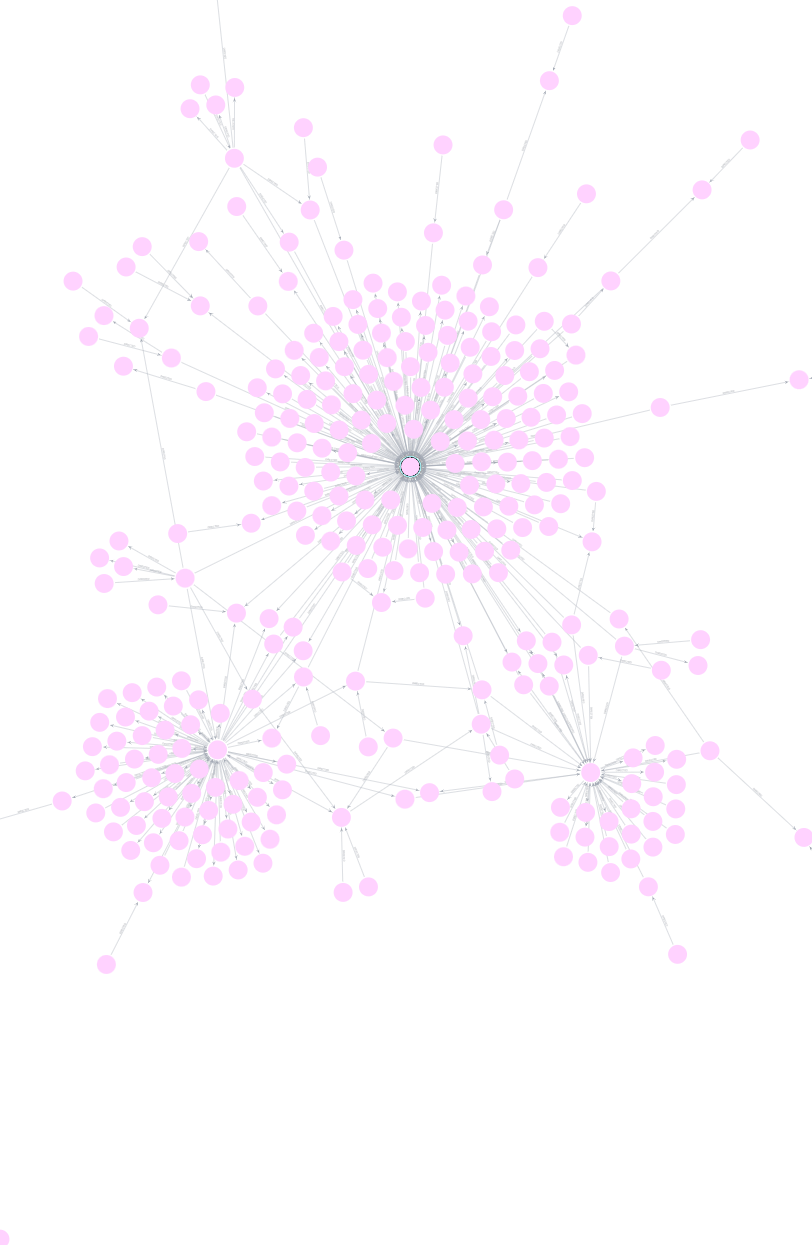

In [ ]:
import asyncio

question = "who killed napoleon?"
mode="mix"

asyncio.run(main(question=question, mode=mode, data_path="/content/rag_storage/data.txt"))

INFO: [base] Database chunk-entity-relation at neo4j+s://25f845c9.databases.neo4j.io not found. Try to create specified database.
INFO: [base] Connected to None at neo4j+s://25f845c9.databases.neo4j.io
INFO: [base] Ensured B-Tree index on entity_id for base in None
INFO: [base] Found existing index 'entity_id_fulltext_idx_base' with state: ONLINE
INFO: [base] Full-text index 'entity_id_fulltext_idx_base' already exists and is online. Skipping recreation.
INFO: Processing 1 document(s)
INFO: Extracting stage 1/1: /content/rag_storage/data.txt
INFO: Processing d-id: doc-c9ae7db6633eaac55083ed5a4188b3b4
INFO: Embedding func: 8 new workers initialized (Timeouts: Func: 30s, Worker: 60s, Health Check: 75s)
INFO: LLM func: 4 new workers initialized (Timeouts: Func: 180s, Worker: 360s, Health Check: 375s)
INFO:  == LLM cache == saving: default:extract:d6d68cd06228a093de1131895b3b74e2
INFO:  == LLM cache == saving: default:extract:924203436e08dab3f5ae88e9efe979fd
INFO:  == LLM cache == saving: 


===== Query Result =====

There is no definitive evidence that anyone "killed" Napoleon Bonaparte, as he died on May 5, 1821, from what is widely accepted to be stomach cancer, as concluded by the autopsy conducted by Dr. François Carlo Antommarchi. While there are numerous theories and speculations about the possible causes of his health deterioration and death, including accusations of mistreatment during his exile to Saint Helena, no conclusive proof supports claims of foul play.

During his time in exile, especially in the years leading up to his death, Napoleon's health declined significantly. He was confined to bed by March 1821, and his health issues worsened until his death at the age of 51. There were also speculations of poor living conditions and treatment by the British authorities who held him captive, leading some supporters to claim he was effectively murdered by neglect, yet this is not universally accepted as intentional assassination. 

### References

- [1] /content

In [ ]:
question = "who was napoleon?"
mode="mix"
asyncio.run(main(question=question, mode=mode,data_path="/content/data.txt"))

INFO: [] Faiss index loaded with 487 vectors from ./rag_storage/faiss_index_entities.index
INFO: [] Faiss index loaded with 388 vectors from ./rag_storage/faiss_index_relationships.index
INFO: [] Faiss index loaded with 47 vectors from ./rag_storage/faiss_index_chunks.index
INFO: [base] Database chunk-entity-relation at neo4j+s://25f845c9.databases.neo4j.io not found. Try to create specified database.
INFO: [base] Connected to None at neo4j+s://25f845c9.databases.neo4j.io
INFO: [base] Ensured B-Tree index on entity_id for base in None
INFO: [base] Found existing index 'entity_id_fulltext_idx_base' with state: ONLINE
INFO: [base] Full-text index 'entity_id_fulltext_idx_base' already exists and is online. Skipping recreation.


FileNotFoundError: Data file not found: /content/data.txt

In [ ]:
question = "nepolian's family"
mode="mix"

asyncio.run(main(question=question, mode=mode, data_path="/content/rag_storage/data.txt"))

INFO: [] Faiss index loaded with 487 vectors from ./rag_storage/faiss_index_entities.index
INFO: [] Faiss index loaded with 388 vectors from ./rag_storage/faiss_index_relationships.index
INFO: [] Faiss index loaded with 47 vectors from ./rag_storage/faiss_index_chunks.index
INFO: [base] Database chunk-entity-relation at neo4j+s://25f845c9.databases.neo4j.io not found. Try to create specified database.
INFO: [base] Connected to None at neo4j+s://25f845c9.databases.neo4j.io
INFO: [base] Ensured B-Tree index on entity_id for base in None
INFO: [base] Found existing index 'entity_id_fulltext_idx_base' with state: ONLINE
INFO: [base] Full-text index 'entity_id_fulltext_idx_base' already exists and is online. Skipping recreation.
INFO: Created 1 duplicate document records with track_id: insert_20260327_103008_d4f3e5d1
INFO: Preserving 1 failed document entries for manual review
INFO: No valid documents to process after consistency check
INFO: Enqueued document processing pipeline stopped
INF


===== Query Result =====

Napoleon Bonaparte belonged to the **Buonaparte family**, which has Italian origins and descends from a minor Tuscan noble family that emigrated to Corsica in the 16th century. His paternal ancestors, the Buonapartes, and his maternal ancestors, the Ramolino family, hailed from Lombardy, with notable ties to nobility. 

Napoleon's immediate family included several siblings: an elder brother, Joseph, and six younger siblings—Lucien, Elisa, Louis, Pauline, Caroline, and Jérôme. Additionally, five more siblings were either stillborn or did not survive infancy. Napoleon was married twice; his first wife was **Joséphine de Beauharnais**, with whom he had a civil marriage in 1796, and they were solemnized in a religious ceremony before his coronation in 1804. However, their marriage was annulled in January 1810 due to the lack of heirs.

He later married **Marie Louise**, an Austrian princess, in April 1810, with whom he had one legitimate child, **Napoleon II** (F

In [ ]:
question = "what were the long-term consequences for Nepal’s borders and foreign policy?"
mode="mix"

asyncio.run(main(question=question, mode=mode, data_path="/content/rag_storage/data.txt"))

INFO: [] Faiss index loaded with 487 vectors from ./rag_storage/faiss_index_entities.index
INFO: [] Faiss index loaded with 388 vectors from ./rag_storage/faiss_index_relationships.index
INFO: [] Faiss index loaded with 47 vectors from ./rag_storage/faiss_index_chunks.index
INFO: [base] Database chunk-entity-relation at neo4j+s://25f845c9.databases.neo4j.io not found. Try to create specified database.
INFO: [base] Connected to None at neo4j+s://25f845c9.databases.neo4j.io
INFO: [base] Ensured B-Tree index on entity_id for base in None
INFO: [base] Found existing index 'entity_id_fulltext_idx_base' with state: ONLINE
INFO: [base] Full-text index 'entity_id_fulltext_idx_base' already exists and is online. Skipping recreation.
INFO: Created 1 duplicate document records with track_id: insert_20260327_103055_afa8fba0
INFO: Preserving 2 failed document entries for manual review
INFO: No valid documents to process after consistency check
INFO: Enqueued document processing pipeline stopped
INF


===== Query Result =====

I do not have enough information to answer that.


In [ ]:
import asyncio

question = "Napoleon's autopsy concluded he died of the same disease as a close family member. Who was that family member, and what was the disease?"
mode="mix"

asyncio.run(main(question=question, mode=mode, data_path="/content/rag_storage/data.txt"))

INFO: [] Faiss index loaded with 487 vectors from ./rag_storage/faiss_index_entities.index
INFO: [] Faiss index loaded with 388 vectors from ./rag_storage/faiss_index_relationships.index
INFO: [] Faiss index loaded with 47 vectors from ./rag_storage/faiss_index_chunks.index
INFO: [base] Database chunk-entity-relation at neo4j+s://25f845c9.databases.neo4j.io not found. Try to create specified database.
INFO: [base] Connected to None at neo4j+s://25f845c9.databases.neo4j.io
INFO: [base] Ensured B-Tree index on entity_id for base in None
INFO: [base] Found existing index 'entity_id_fulltext_idx_base' with state: ONLINE
INFO: [base] Full-text index 'entity_id_fulltext_idx_base' already exists and is online. Skipping recreation.
INFO: Created 1 duplicate document records with track_id: insert_20260327_103403_b3c35e6c
INFO: Preserving 3 failed document entries for manual review
INFO: No valid documents to process after consistency check
INFO: Enqueued document processing pipeline stopped
INF


===== Query Result =====

Napoleon's autopsy concluded that he died of **stomach cancer**. This was the same disease that had killed his **father**. This diagnosis was supported by multiple autopsy reports, including one by François Carlo Antommarchi, who noted that Napoleon died from internal bleeding caused by stomach cancer, mirroring the fate of his father. 

### References

- [1] Content from the source detailing Napoleon's cause of death and family history.


In [ ]:
import asyncio

question = "How many years passed between Napoleon's death and the final entombment of his remains in the crypt at Les Invalides?"
mode="mix"

asyncio.run(main(question=question, mode=mode, data_path="/content/rag_storage/data.txt"))

INFO: [] Faiss index loaded with 487 vectors from ./rag_storage/faiss_index_entities.index
INFO: [] Faiss index loaded with 388 vectors from ./rag_storage/faiss_index_relationships.index
INFO: [] Faiss index loaded with 47 vectors from ./rag_storage/faiss_index_chunks.index
INFO: [base] Database chunk-entity-relation at neo4j+s://25f845c9.databases.neo4j.io not found. Try to create specified database.
INFO: [base] Connected to None at neo4j+s://25f845c9.databases.neo4j.io
INFO: [base] Ensured B-Tree index on entity_id for base in None
INFO: [base] Found existing index 'entity_id_fulltext_idx_base' with state: ONLINE
INFO: [base] Full-text index 'entity_id_fulltext_idx_base' already exists and is online. Skipping recreation.
INFO: Created 1 duplicate document records with track_id: insert_20260327_103522_f862a600
INFO: Preserving 4 failed document entries for manual review
INFO: No valid documents to process after consistency check
INFO: Enqueued document processing pipeline stopped
INF


===== Query Result =====

Napoleon died on May 5, 1821. His remains were finally entombed in the crypt at Les Invalides in 1861. 

To calculate the years that passed between these two events:

1861 - 1821 = 40 years

Therefore, 40 years passed between Napoleon's death and the final entombment of his remains in the crypt at Les Invalides.

### References

- [1] /content/rag_storage/data.txt


In [ ]:
import asyncio

question = "Napoleon named a successor upon his 1815 abdication — did that successor ever produce an heir to continue the Bonaparte line? What ultimately happened to him?"
mode="mix"

asyncio.run(main(question=question, mode=mode, data_path="/content/rag_storage/data.txt"))

INFO: [] Faiss index loaded with 487 vectors from ./rag_storage/faiss_index_entities.index
INFO: [] Faiss index loaded with 388 vectors from ./rag_storage/faiss_index_relationships.index
INFO: [] Faiss index loaded with 47 vectors from ./rag_storage/faiss_index_chunks.index
INFO: [base] Database chunk-entity-relation at neo4j+s://25f845c9.databases.neo4j.io not found. Try to create specified database.
INFO: [base] Connected to None at neo4j+s://25f845c9.databases.neo4j.io
INFO: [base] Ensured B-Tree index on entity_id for base in None
INFO: [base] Found existing index 'entity_id_fulltext_idx_base' with state: ONLINE
INFO: [base] Full-text index 'entity_id_fulltext_idx_base' already exists and is online. Skipping recreation.
INFO: Created 1 duplicate document records with track_id: insert_20260327_103634_d28c97a8
INFO: Preserving 5 failed document entries for manual review
INFO: No valid documents to process after consistency check
INFO: Enqueued document processing pipeline stopped
INF


===== Query Result =====

Upon his abdication in 1815, Napoleon named his son, François Charles Joseph Napoleon, also known as Napoleon II or the King of Rome, as his successor. However, Napoleon II did not produce any heirs to continue the Bonaparte line. He was awarded the title of Duke of Reichstadt in 1818 but tragically died of tuberculosis at the age of 21 on July 22, 1832. His untimely death marked the end of the direct lineage from Napoleon I, leaving no descendants to continue the Bonaparte name through him. 

### References

- [1] /content/rag_storage/data.txt


In [ ]:
import asyncio

question = "A theory emerged that Napoleon was poisoned by arsenic. What two pieces of evidence from hair sample analysis were used to challenge this theory?"
mode="mix"

asyncio.run(main(question=question, mode=mode, data_path="/content/rag_storage/data.txt"))

INFO: [] Faiss index loaded with 487 vectors from ./rag_storage/faiss_index_entities.index
INFO: [] Faiss index loaded with 388 vectors from ./rag_storage/faiss_index_relationships.index
INFO: [] Faiss index loaded with 47 vectors from ./rag_storage/faiss_index_chunks.index
INFO: [base] Database chunk-entity-relation at neo4j+s://25f845c9.databases.neo4j.io not found. Try to create specified database.
INFO: [base] Connected to None at neo4j+s://25f845c9.databases.neo4j.io
INFO: [base] Ensured B-Tree index on entity_id for base in None
INFO: [base] Found existing index 'entity_id_fulltext_idx_base' with state: ONLINE
INFO: [base] Full-text index 'entity_id_fulltext_idx_base' already exists and is online. Skipping recreation.
INFO: Created 1 duplicate document records with track_id: insert_20260327_103853_6d8c4303
INFO: Preserving 6 failed document entries for manual review
INFO: No valid documents to process after consistency check
INFO: Enqueued document processing pipeline stopped
INF


===== Query Result =====

The theory that Napoleon was poisoned by arsenic emerged based on hair sample analysis showing high concentrations of arsenic. However, this theory has been challenged for two significant reasons:

1. **Presence of Arsenic in Other Hair Samples**: Subsequent studies found high concentrations of arsenic not only in samples from Napoleon's hair but also in hair samples from his childhood and those of his son and Joséphine. This suggested that the arsenic found in Napoleon's hair could have originated from environmental exposure rather than intentional poisoning.

2. **Use of Arsenic in Medicinal Products**: During the 19th century, arsenic was commonly used in various medications and products, such as hair creams. This widespread use implies that the arsenic detected in Napoleon's hair could be attributed to external sources rather than deliberate poisoning.

These points were crucial in questioning the validity of the arsenic poisoning theory. 

### References

In [ ]:
import asyncio

question = "The return of Napoleon's remains to France in 1840 was tied to the political ambitions of one ruler, and the legend it fueled enabled the rise of another. Who were these two rulers?"
mode="mix"

asyncio.run(main(question=question, mode=mode, data_path="/content/rag_storage/data.txt"))

INFO: [] Faiss index loaded with 487 vectors from ./rag_storage/faiss_index_entities.index
INFO: [] Faiss index loaded with 388 vectors from ./rag_storage/faiss_index_relationships.index
INFO: [] Faiss index loaded with 47 vectors from ./rag_storage/faiss_index_chunks.index
INFO: [base] Database chunk-entity-relation at neo4j+s://25f845c9.databases.neo4j.io not found. Try to create specified database.
INFO: [base] Connected to None at neo4j+s://25f845c9.databases.neo4j.io
INFO: [base] Ensured B-Tree index on entity_id for base in None
INFO: [base] Found existing index 'entity_id_fulltext_idx_base' with state: ONLINE
INFO: [base] Full-text index 'entity_id_fulltext_idx_base' already exists and is online. Skipping recreation.
INFO: Created 1 duplicate document records with track_id: insert_20260327_104258_f5bdbb90
INFO: Preserving 7 failed document entries for manual review
INFO: No valid documents to process after consistency check
INFO: Enqueued document processing pipeline stopped
INF


===== Query Result =====

The return of Napoleon's remains to France in 1840 was closely tied to Louis-Philippe, who sought to prop up his unpopular regime by associating it with the legendary figure of Napoleon. This political maneuver was instrumental in bolstering Louis-Philippe's authority during a time of decline in his popularity. Furthermore, the enduring resonance of the Napoleonic legend eventually facilitated the rise of Napoleon III, who capitalized on this legacy to establish his own regime in France.

### References

- [1] /content/rag_storage/data.txt


In [ ]:
import asyncio

question = "Napoleon's military campaign in one European country indirectly triggered independence movements thousands of miles away. Trace the chain: which country was invaded, what power vacuum resulted, and name two leaders who filled it?"
mode="mix"

asyncio.run(main(question=question, mode=mode, data_path="/content/rag_storage/data.txt"))

INFO: [] Faiss index loaded with 487 vectors from ./rag_storage/faiss_index_entities.index
INFO: [] Faiss index loaded with 388 vectors from ./rag_storage/faiss_index_relationships.index
INFO: [] Faiss index loaded with 47 vectors from ./rag_storage/faiss_index_chunks.index
INFO: [base] Database chunk-entity-relation at neo4j+s://25f845c9.databases.neo4j.io not found. Try to create specified database.
INFO: [base] Connected to None at neo4j+s://25f845c9.databases.neo4j.io
INFO: [base] Ensured B-Tree index on entity_id for base in None
INFO: [base] Found existing index 'entity_id_fulltext_idx_base' with state: ONLINE
INFO: [base] Full-text index 'entity_id_fulltext_idx_base' already exists and is online. Skipping recreation.
INFO: Created 1 duplicate document records with track_id: insert_20260327_104600_932c5a9d
INFO: Preserving 8 failed document entries for manual review
INFO: No valid documents to process after consistency check
INFO: Enqueued document processing pipeline stopped
INF


===== Query Result =====

Napoleon's military campaign in **Spain** indirectly triggered independence movements in Latin America. When Napoleon invaded Spain in 1808 and ousted the **Spanish Bourbon Monarchy**, a significant power vacuum was created. This disruption allowed local political leaders in Spanish America to rise to power, as many sought to rule in the name of **Ferdinand VII**, whom they considered the legitimate monarch.

Two notable leaders who emerged from this power vacuum and led movements for independence were:

1. **Simón Bolívar**, who became a key figure in the liberation of several South American countries.
2. **José de San Martín**, who played a crucial role in leading independence movements in Argentina, Chile, and Peru.

These leaders were influenced by the nationalist sentiments that arose during Napoleon's campaigns and sought to establish independent nations in their respective regions. 

### References

- [1] Document Title One


In [ ]:
import asyncio

question = "Napoleon named a successor at his 1815 abdication. That successor died without heirs, making the Napoleonic legend the only thing capable of continuing Bonaparte political power. The ruler whose rise that legend enabled commissioned Napoleon's permanent tomb — who designed it, and during whose reign was it completed?"
mode="mix"

asyncio.run(main(question=question, mode=mode, data_path="/content/rag_storage/data.txt"))

INFO: [] Faiss index loaded with 487 vectors from ./rag_storage/faiss_index_entities.index
INFO: [] Faiss index loaded with 388 vectors from ./rag_storage/faiss_index_relationships.index
INFO: [] Faiss index loaded with 47 vectors from ./rag_storage/faiss_index_chunks.index
INFO: [base] Database chunk-entity-relation at neo4j+s://25f845c9.databases.neo4j.io not found. Try to create specified database.
INFO: [base] Connected to None at neo4j+s://25f845c9.databases.neo4j.io
INFO: [base] Ensured B-Tree index on entity_id for base in None
INFO: [base] Found existing index 'entity_id_fulltext_idx_base' with state: ONLINE
INFO: [base] Full-text index 'entity_id_fulltext_idx_base' already exists and is online. Skipping recreation.
INFO: Created 1 duplicate document records with track_id: insert_20260327_105212_f73056fe
INFO: Preserving 9 failed document entries for manual review
INFO: No valid documents to process after consistency check
INFO: Enqueued document processing pipeline stopped
INF


===== Query Result =====

Napoleon named his son, Napoleon Francis Joseph Charles, as his successor at his 1815 abdication. However, he died without heirs, which allowed the Napoleonic legend to persist as the only means of maintaining Bonaparte political power.

The ruler who rose to power based on this legend was Napoleon III. He commissioned Napoleon's permanent tomb, which was designed by Louis Visconti. The tomb was completed during Napoleon III's reign in 1861. This tomb is located at Les Invalides in Paris, which is also the final resting place of Napoleon Bonaparte.

### References

- [1] /content/rag_storage/data.txt


In [ ]:
import asyncio

question = "Napoleon abdicated in 1815. Trace the full chain from that abdication to the physical location of his remains today — naming every key person, decision, and year along the way."
mode="mix"

asyncio.run(main(question=question, mode=mode, data_path="/content/rag_storage/data.txt"))

INFO: [] Faiss index loaded with 487 vectors from ./rag_storage/faiss_index_entities.index
INFO: [] Faiss index loaded with 388 vectors from ./rag_storage/faiss_index_relationships.index
INFO: [] Faiss index loaded with 47 vectors from ./rag_storage/faiss_index_chunks.index
INFO: [base] Database chunk-entity-relation at neo4j+s://25f845c9.databases.neo4j.io not found. Try to create specified database.
INFO: [base] Connected to None at neo4j+s://25f845c9.databases.neo4j.io
INFO: [base] Ensured B-Tree index on entity_id for base in None
INFO: [base] Found existing index 'entity_id_fulltext_idx_base' with state: ONLINE
INFO: [base] Full-text index 'entity_id_fulltext_idx_base' already exists and is online. Skipping recreation.
INFO: Created 1 duplicate document records with track_id: insert_20260327_112210_020fe03e
INFO: Preserving 10 failed document entries for manual review
INFO: No valid documents to process after consistency check
INFO: Enqueued document processing pipeline stopped
IN


===== Query Result =====

Napoleon's abdication in 1815 marked a significant turning point not only in his life but also in European history. Below is a detailed chain tracing the events from his abdication to the present-day location of his remains:

### Key Events from Abdication to Burial

1. **1815 - Abdication**: 
   - After being decisively defeated at the **Battle of Waterloo** on June 18, 1815, Napoleon returned to Paris but found that the legislature had turned against him. Recognizing that his position was untenable, he abdicated on June 22, 1815, in favor of his son, Napoleon II.

2. **1815 - Exile to Saint Helena**: 
   - Following his abdication, Napoleon attempted to flee to the United States but ultimately surrendered to British forces. He was then exiled to **Saint Helena**, a remote island in the South Atlantic, where he was held as a prisoner. He arrived at Saint Helena on October 15, 1815.

3. **1821 - Death**:
   - Napoleon's health deteriorated during his time on 

# Failed at 8 hopes reasoning !

In [ ]:
import asyncio

question = "Napoleon's reorganization of a fragmented empire set off a chain reaction that culminated in German unification. Trace the complete chain from the original number of states, through the reorganization, through the nationalism it sparked, to a precise calculation of how many years after Napoleon's death unification occurred — and name the second nation that underwent an identical process"
mode="mix"

asyncio.run(main(question=question, mode=mode, data_path="/content/rag_storage/data.txt"))

INFO: [] Faiss index loaded with 487 vectors from ./rag_storage/faiss_index_entities.index
INFO: [] Faiss index loaded with 388 vectors from ./rag_storage/faiss_index_relationships.index
INFO: [] Faiss index loaded with 47 vectors from ./rag_storage/faiss_index_chunks.index
INFO: [base] Database chunk-entity-relation at neo4j+s://25f845c9.databases.neo4j.io not found. Try to create specified database.
INFO: [base] Connected to None at neo4j+s://25f845c9.databases.neo4j.io
INFO: [base] Ensured B-Tree index on entity_id for base in None
INFO: [base] Found existing index 'entity_id_fulltext_idx_base' with state: ONLINE
INFO: [base] Full-text index 'entity_id_fulltext_idx_base' already exists and is online. Skipping recreation.
INFO: Created 1 duplicate document records with track_id: insert_20260327_112719_26ea214c
INFO: Preserving 11 failed document entries for manual review
INFO: No valid documents to process after consistency check
INFO: Enqueued document processing pipeline stopped
IN


===== Query Result =====

Napoleon's reorganization of the fragmented territories of the Holy Roman Empire was a significant precursor to German unification. Below is a detailed trace of this chain reaction:

### Original Fragmentation of States
The Holy Roman Empire was characterized by its fragmentation, consisting of approximately **three hundred** individual states (referred to as "Kleinstaaterei"). This multitude of states varied greatly in size, governance, and political power.

### Reorganization by Napoleon
As a result of his military conquests and political strategies, Napoleon effectively dissolved the Holy Roman Empire. He reorganized these states into a more streamlined political entity known as the **Confederation of the Rhine**. This confederation served as a buffer zone designed to consolidate French influence in Central Europe and included a collection of German states, thus simplifying governance and laying the groundwork for future nationalism.

### Emergence of Nati

# Worked at 7 hopes ! let's try some more !

In [ ]:
import asyncio

question = "Napoleon's legacy is assessed differently across the world. Trace the chain from his invasion of Spain, through the power vacuum it created, through the independence leaders it produced, through the nationalist ideology they carried — to the single country that uniquely honors Napoleon in a place no other country does, and explain why"
mode="mix"

asyncio.run(main(question=question, mode=mode, data_path="/content/rag_storage/data.txt"))

INFO: [] Faiss index loaded with 487 vectors from ./rag_storage/faiss_index_entities.index
INFO: [] Faiss index loaded with 388 vectors from ./rag_storage/faiss_index_relationships.index
INFO: [] Faiss index loaded with 47 vectors from ./rag_storage/faiss_index_chunks.index
INFO: [base] Database chunk-entity-relation at neo4j+s://25f845c9.databases.neo4j.io not found. Try to create specified database.
INFO: [base] Connected to None at neo4j+s://25f845c9.databases.neo4j.io
INFO: [base] Ensured B-Tree index on entity_id for base in None
INFO: [base] Found existing index 'entity_id_fulltext_idx_base' with state: ONLINE
INFO: [base] Full-text index 'entity_id_fulltext_idx_base' already exists and is online. Skipping recreation.
INFO: Created 1 duplicate document records with track_id: insert_20260327_113013_c8146d60
INFO: Preserving 12 failed document entries for manual review
INFO: No valid documents to process after consistency check
INFO: Enqueued document processing pipeline stopped
IN


===== Query Result =====

Napoleon Bonaparte's legacy has had a profound impact, particularly in Latin America, stemming from his invasion of Spain in 1808. This act not only marked the beginning of the Peninsular War but also created a significant power vacuum that would eventually influence the course of independence movements throughout Latin America.

### The Invasion of Spain and Its Consequences

When Napoleon invaded the Iberian Peninsula, he installed his brother Joseph as King of Spain. This usurpation led to widespread unrest and conflict, as many Spanish citizens resisted French control. The resultant chaos created a vacuum of power that undermined the traditional Spanish monarchy, provoking local leaders and nationalists to step forward in the absence of effective governance. 

### Emergence of Independence Leaders

As Spanish authority weakened, numerous independence movements gained momentum across Latin America. Key figures such as **Simón Bolívar** and **José de San Ma